# Weekly Demand Forecasting & Inventory Policy for an FMCG Distributor
3 warehouses (Mumbai, Pune, Nagpur) × 40 SKUs × 4 years of weekly sell-in · statistical vs machine-learning forecasters · rolling-origin backtests · safety stock & inventory simulation

> Synthetic data: `src/generate_data.py` (seed 31).

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
from forecasting import *
import charts
sales, sku, cal = load()
sales.head()

,week,warehouse,sku,units_sold,stockout_flag,on_promotion
0,2022-01-03,MUM,BEV01,557,0,0
1,2022-01-10,MUM,BEV01,600,0,0
2,2022-01-17,MUM,BEV01,701,0,0
3,2022-01-24,MUM,BEV01,520,0,0
4,2022-01-31,MUM,BEV01,541,0,0


## 1. Clean the target: censored demand
In stock-out weeks, *sales* understate *demand*. Training on raw sales would teach the model that supply failures are normal. Stock-out weeks are re-estimated from neighbouring in-stock, non-promo weeks.

In [2]:
sales = correct_censored_demand(sales)
print(f"{(sales.demand_correction > 0).sum()} stock-out weeks corrected, {sales.demand_correction.sum():,.0f} units of hidden demand recovered ({sales.demand_correction.sum() / sales.units_sold.sum():.1%} of sales)")
df = to_long(sales, cal)
df.head()

644 stock-out weeks corrected, 134,282 units of hidden demand recovered (1.5% of sales)


,unique_id,ds,y,on_promotion,diwali_weight,holi_weight,ganesh_weight,eid_weight
0,MUM|BEV01,2022-01-03,557.0,0,0.0,0.0,0.0,0.0
1,MUM|BEV01,2022-01-10,600.0,0,0.0,0.0,0.0,0.0
2,MUM|BEV01,2022-01-17,701.0,0,0.0,0.0,0.0,0.0
3,MUM|BEV01,2022-01-24,520.0,0,0.0,0.0,0.0,0.0
4,MUM|BEV01,2022-01-31,541.0,0,0.0,0.0,0.0,0.0


## 2. ABC-XYZ segmentation
A = top 80% of inventory value, B = next 15%, C = last 5%. X/Y/Z = weekly coefficient of variation ≤0.25 / ≤0.5 / >0.5.

,count
class,
AY,33
CY,28
BY,19
CZ,19
AX,10
BX,9
CX,2


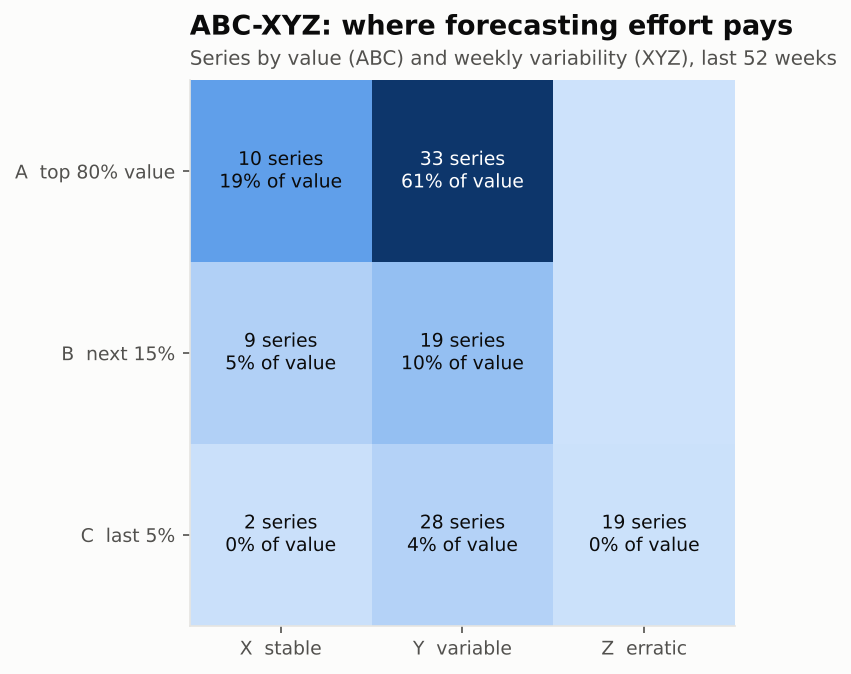

In [3]:
classes = abc_xyz(sales, sku)
charts.abc_xyz_chart(classes)
display(classes['class'].value_counts().to_frame())
display(Image('../images/abc_xyz.png'))

## 3. Backtest: 8 forecasters, 4 rolling origins × 13-week horizon
| Family | Models |
|---|---|
| Baseline | Seasonal naive (same week last year) |
| Statistical (statsforecast) | AutoETS, AutoTheta, MSTL, Croston, TSB (last two for intermittent demand) |
| Machine learning (mlforecast) | One **global LightGBM** across all 120 series, with lags 1-4/13/52, rolling stats, calendar, promo flag and festival-calendar features, log target |
| Ensemble | median(LightGBM, AutoETS, MSTL) |

AutoARIMA with a 52-week season was tried and dropped: about 75 s per series in backtesting, impractical at 120 series.

In [4]:
cv = backtest(df)
overall = scores(cv)
festive = festival_scores(cv, cal)
display(overall.merge(festive, on=['group', 'model'], suffixes=('', '_diwali_weeks')).sort_values('wape_pct'))

,group,model,wape_pct,bias_pct,wape_pct_diwali_weeks,bias_pct_diwali_weeks
6,All,LightGBM,20.2,-3.8,23.3,-9.6
7,All,Ensemble,21.2,-3.9,25.2,-14.5
2,All,AutoTheta,22.6,-1.7,28.0,-17.7
3,All,MSTL,23.2,-1.9,25.6,-11.4
4,All,Croston,23.4,-2.5,28.3,-20.0
1,All,AutoETS,23.5,-2.3,27.8,-18.9
5,All,TSB,24.0,-2.4,28.4,-19.5
0,All,SeasonalNaive,28.0,-4.0,30.2,-15.8


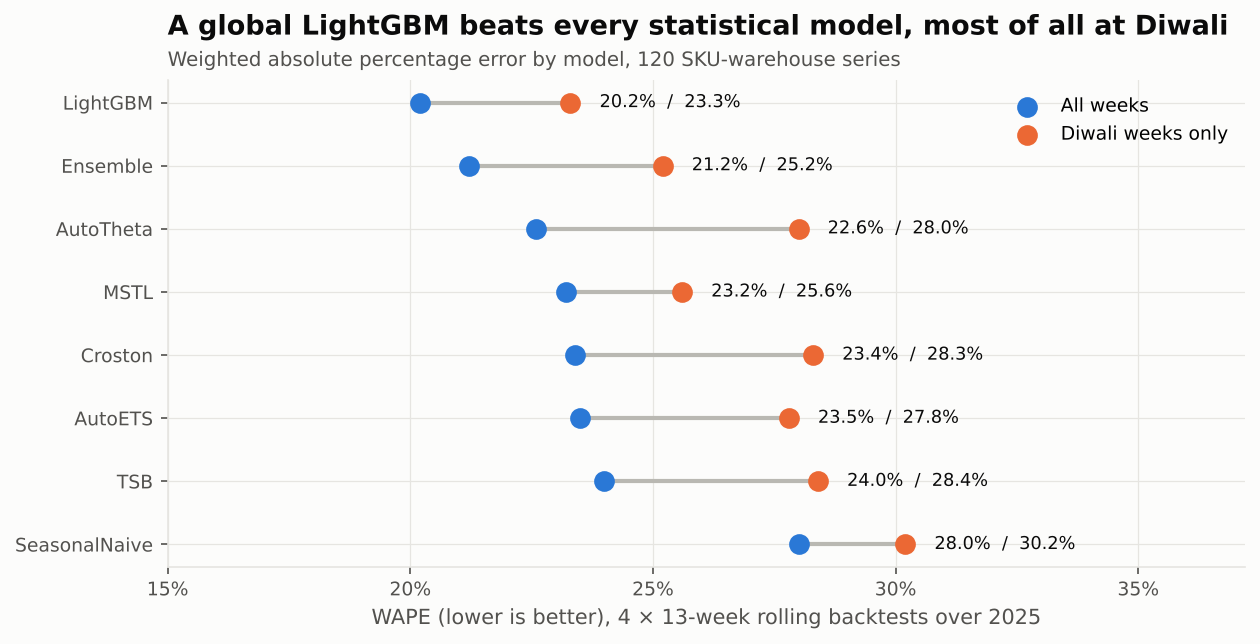

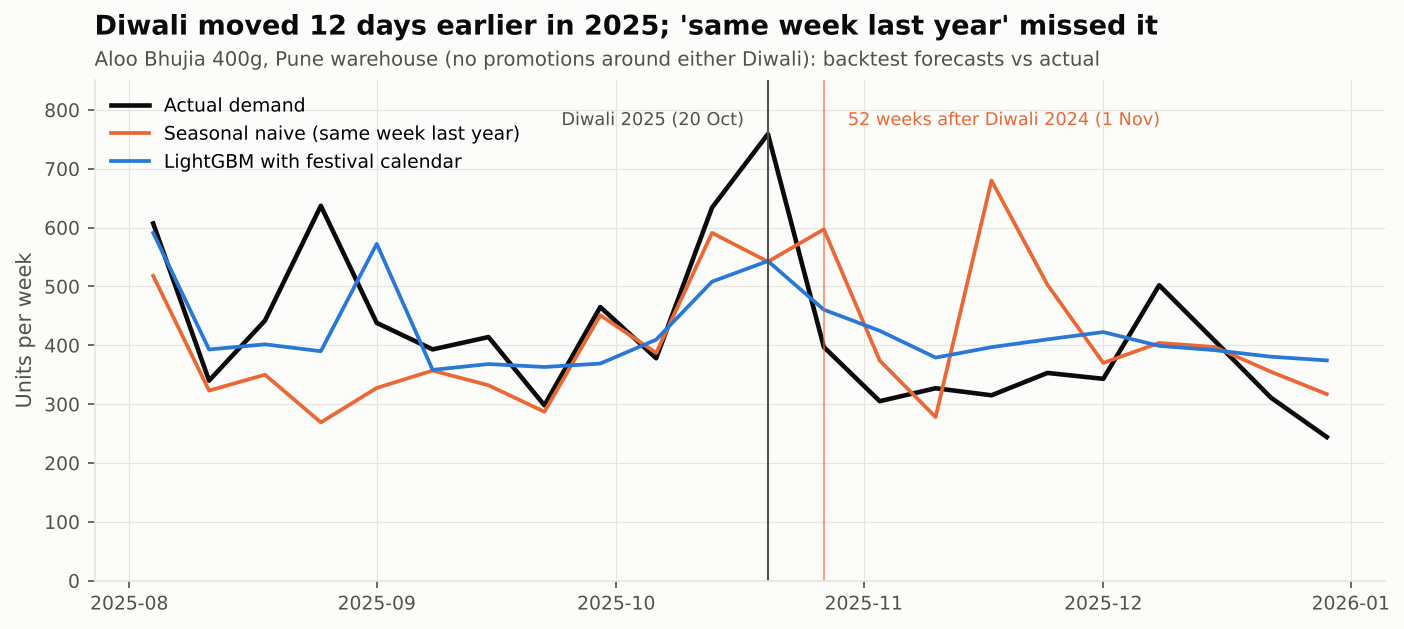

In [5]:
charts.wape_chart(overall, festive)
charts.diwali_shift(cv, cal)
display(Image('../images/model_wape.png'))
display(Image('../images/diwali_shift.png'))

### Best model by ABC-XYZ class

In [6]:
best_model_per_class(cv, classes)

,model,wape_pct,bias_pct,seasonal_naive_wape_pct,series
class,,,,,
AX,Croston,18.0,-1.0,25.2,10
AY,LightGBM,20.9,-4.5,28.5,33
BX,LightGBM,17.6,-1.4,23.8,9
BY,LightGBM,20.2,-0.5,27.7,19
CX,TSB,17.3,-2.5,28.8,2
CY,LightGBM,20.0,-2.8,29.3,28
CZ,LightGBM,43.0,-21.5,63.1,19


### Intermittent festive SKUs
Gift boxes, diyas and rangoli sell almost only in Diwali week. No time-series model handles them well; they should be planned as **events** (pre-booked quantities from last year's festival sell-through), not forecast weekly.

In [7]:
d = cv.merge(classes[['unique_id', 'sku']])
scores(d[d.sku.str.startswith('FST')]).sort_values('wape_pct')

,group,model,wape_pct,bias_pct
6,All,LightGBM,71.8,-45.7
7,All,Ensemble,83.4,-29.7
3,All,MSTL,99.4,-4.1
5,All,TSB,102.8,-34.6
4,All,Croston,104.3,-30.7
1,All,AutoETS,106.0,-19.9
2,All,AutoTheta,106.7,-17.5
0,All,SeasonalNaive,112.3,-6.1


## 4. From forecast to inventory
Safety stock = z × σ(forecast error) × √lead-time. A weekly order-up-to policy is simulated over 2025 for each model across service-level targets. The fair comparison is **how much stock each forecast needs to reach the same fill rate**.

,service_level_target,fill_rate_pct,avg_inventory_value_lakh
model,,,
SeasonalNaive,0.7,99.51,215.8
AutoETS,0.7,99.52,218.6
MSTL,0.6,99.55,197.9
LightGBM,0.5,99.62,165.5
Ensemble,0.6,99.67,184.6


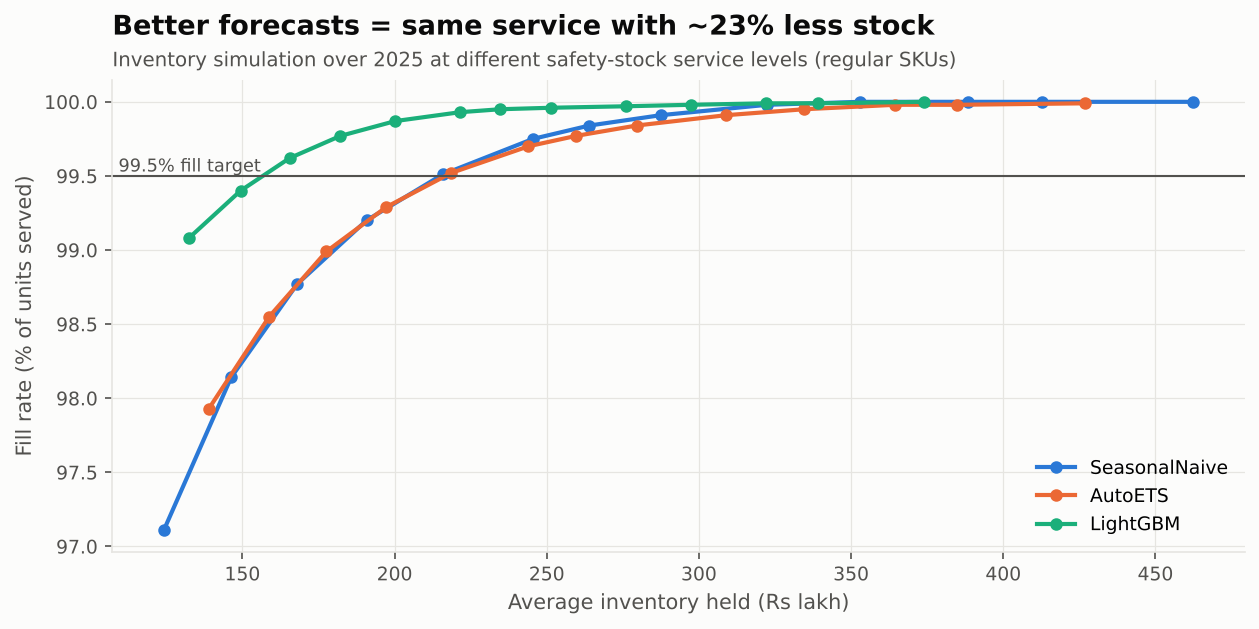

In [8]:
grid = (0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 0.975, 0.99, 0.995, 0.999)
curves = {m: pd.DataFrame([simulate_inventory(cv, m, sku, sl) for sl in grid]) for m in ['SeasonalNaive', 'AutoETS', 'LightGBM']}
charts.inventory_tradeoff(curves)
matched = inventory_at_matched_fill(cv, sku, ['SeasonalNaive', 'AutoETS', 'MSTL', 'LightGBM', 'Ensemble'], 99.5, grid)
display(matched)
display(Image('../images/inventory_tradeoff.png'))

In [9]:
saving = matched.loc['SeasonalNaive', 'avg_inventory_value_lakh'] - matched.loc['LightGBM', 'avg_inventory_value_lakh']
print(f'Working capital released at the same 99.5% fill rate: Rs {saving:.0f} lakh '
      f'({saving / matched.loc["SeasonalNaive", "avg_inventory_value_lakh"]:.0%} less stock)')

Working capital released at the same 99.5% fill rate: Rs 50 lakh (23% less stock)


## 5. Next-quarter forecast (Q1 2026) with prediction intervals
Trained on all history. 80/95% conformal intervals come from 3 backtest windows. The festival calendar (Holi 4-Mar, Eid 20-Mar-2026) is known in advance and fed as future features.

,unique_id,ds,LightGBM,LightGBM-lo-95,LightGBM-lo-80,LightGBM-hi-80,LightGBM-hi-95
0,MUM|BEV01,2026-01-05,921.963661,217.654933,367.436891,1476.490432,1626.272390
1,MUM|BEV01,2026-01-12,924.175758,253.509438,307.080290,1541.271226,1594.842077
2,MUM|BEV01,2026-01-19,963.365135,110.411805,128.632254,1798.098016,1816.318465
3,MUM|BEV01,2026-01-26,983.848406,535.715832,564.346635,1403.350178,1431.980980
4,MUM|BEV01,2026-02-02,971.220555,506.237537,546.774924,1395.666187,1436.203574


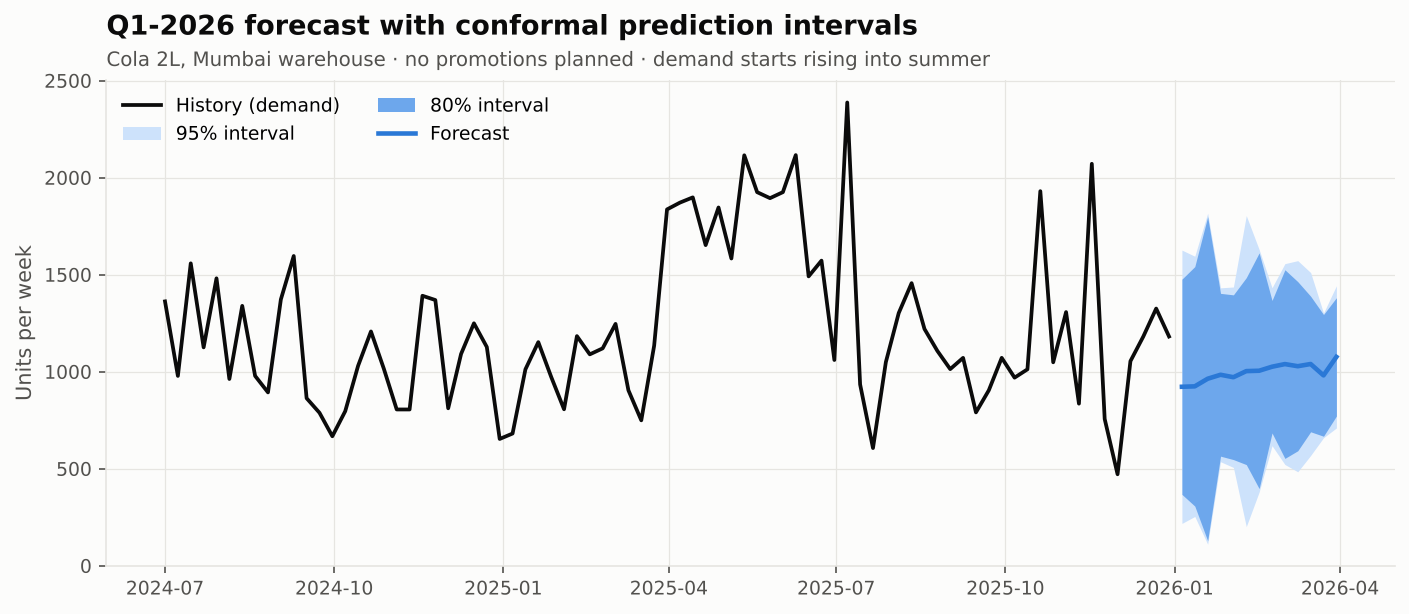

In [10]:
fc = forecast_next_quarter(df, cal.rename(columns={'week': 'ds'}))
fc.to_csv('../reports/forecast_q1_2026.csv', index=False)
charts.next_quarter(df, fc)
display(fc.head())
display(Image('../images/next_quarter_forecast.png'))

In [11]:
policy = safety_stock_policy(cv, 'LightGBM', sku, 0.95)
policy.to_csv('../reports/safety_stock_policy.csv')
policy.sort_values('safety_stock_value_inr', ascending=False).head(10)

,sigma_weekly_error,sku,lead_time_weeks,unit_cost_inr,safety_stock_units,safety_stock_value_inr
unique_id,,,,,,
MUM|NDL01,338.088001,NDL01,2,643.0,787.0,506041.0
MUM|SNK04,441.453186,SNK04,2,477.0,1027.0,489879.0
MUM|BEV01,364.763329,BEV01,2,557.0,849.0,472893.0
MUM|STP05,227.762429,STP05,3,586.0,649.0,380314.0
MUM|PC01,253.852580,PC01,2,614.0,591.0,362874.0
MUM|BEV03,574.080186,BEV03,2,269.0,1336.0,359384.0
MUM|SNK03,306.367021,SNK03,2,462.0,713.0,329406.0
MUM|HC01,214.880758,HC01,2,619.0,500.0,309500.0
PUN|BEV01,229.140222,BEV01,2,557.0,534.0,297438.0
